# 01 · Análisis Exploratorio — Gemelo Digital Energía vs Clima

## ¿Qué es un análisis exploratorio?

Antes de construir modelos o sacar conclusiones, necesitamos **conocer los datos**.
El análisis exploratorio (EDA, *Exploratory Data Analysis*) responde preguntas básicas:

- ¿Cuántos datos tenemos? ¿En qué rango temporal?
- ¿Hay valores que faltan (*nulls*)? ¿Valores extremos (*outliers*)?
- ¿Cómo se distribuyen las variables? ¿Siguen alguna forma conocida?
- ¿Se ven patrones a simple vista en las series temporales?

Sin este paso, cualquier modelo que construyamos puede estar basado en datos
sucios o mal entendidos. Es la base de todo análisis de datos serio.

---
**Fuentes de datos:**
- 🌤️ **Open-Meteo** — temperatura, humedad, viento, nubosidad y radiación solar en Madrid
- ⚡ **Demanda eléctrica** — generada sintéticamente con correlación real a la temperatura


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from analysis.data_loader import load_weather, load_energy, load_merged

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('Librerias cargadas OK')

Librerias cargadas OK


## 1. Carga de datos desde InfluxDB

Cargamos los datos de la base de datos de series temporales.
El parámetro `hours` controla el intervalo a recuperar.

> **¿Por qué InfluxDB?** Es una base de datos diseñada específicamente para
> series temporales (datos con marca de tiempo). Es mucho más rápida que
> SQLite o PostgreSQL para este tipo de consultas, y permite hacer agregaciones
> temporales (por hora, día, semana) de forma nativa.


In [2]:
# Cargamos 365 días de datos
HORAS = 365 * 24

weather = load_weather(hours=HORAS)
energy  = load_energy(hours=HORAS)
df      = load_merged(hours=HORAS)

print(f"Clima:   {len(weather):>5} registros  |  {str(weather.index.min())[:19]} → {str(weather.index.max())[:19]}")
print(f"Energia: {len(energy):>5} registros  |  {str(energy.index.min())[:19]} → {str(energy.index.max())[:19]}")
print(f"Merged:  {len(df):>5} filas combinadas")
print(f"\nColumnas disponibles: {list(df.columns)}")

Clima:    8762 registros  |  2025-05-26 12:00:00 → 2026-05-26 11:00:00
Energia:  8810 registros  |  2025-05-26 12:00:00 → 2026-05-26 11:00:00
Merged:   8760 filas combinadas

Columnas disponibles: ['temperature_c', 'humidity_pct', 'wind_speed_kmh', 'cloud_cover_pct', 'solar_radiation_wm2', 'demand_mw', 'hour', 'weekday', 'is_weekend']


## 2. Estadísticas descriptivas

`.describe()` calcula en una sola llamada las métricas más importantes de cada variable:

| Métrica | Qué significa |
|---------|--------------|
| `count` | Número de valores no nulos |
| `mean`  | Media aritmética |
| `std`   | Desviación estándar — qué tanto varía la variable |
| `min / max` | Valores extremos |
| `25% / 50% / 75%` | Percentiles — 50% es la mediana |

> **Truco:** Si `mean` y `50%` (mediana) son muy distintos, la distribución
> está sesgada — hay valores extremos que tiran de la media.


In [3]:
print('=== VARIABLES CLIMATICAS ===')
display(weather.describe().round(2))
print('\n=== DEMANDA ELECTRICA ===')
display(energy.describe().round(2))

=== VARIABLES CLIMATICAS ===


,temperature_c,humidity_pct,wind_speed_kmh,cloud_cover_pct,solar_radiation_wm2
count,8762.00,8762.00,8762.00,8762.00,8762.00
mean,16.78,56.14,8.41,48.17,199.50
std,9.46,26.02,5.08,42.66,281.35
min,-3.00,6.00,0.00,0.00,0.00
25%,8.80,33.00,4.40,2.00,0.00
50%,15.80,55.00,7.50,41.00,10.00
75%,24.00,80.00,11.50,99.00,359.00
max,40.70,100.00,36.90,100.00,989.00



=== DEMANDA ELECTRICA ===


,demand_mw
count,8810.00
mean,24290.97
std,5399.28
min,16000.00
25%,20004.23
50%,24207.15
75%,27727.28
max,43069.10


## 3. Detección de valores nulos

Los valores nulos son huecos en los datos — horas donde el sensor no registró
o la API no respondió. Tenemos que cuantificarlos antes de analizar.

Si hay demasiados nulos en un período, los patrones que encontremos pueden
ser falsos. Por ejemplo: si los nulos aparecen siempre de madrugada, la media
diaria calculada sin saberlo estaría sesgada hacia las horas diurnas.


In [4]:
print('Nulos en clima:')
nulos_clima = weather.isnull().sum()
for col, n in nulos_clima.items():
    estado = '✓ OK' if n == 0 else f'⚠ {n} nulos ({n/len(weather)*100:.1f}%)'
    print(f'  {col:<25} {estado}')

print('\nNulos en energía:')
nulos_energia = energy.isnull().sum()
for col, n in nulos_energia.items():
    estado = '✓ OK' if n == 0 else f'⚠ {n} nulos'
    print(f'  {col:<25} {estado}')

Nulos en clima:
  temperature_c             ✓ OK
  humidity_pct              ✓ OK
  wind_speed_kmh            ✓ OK
  cloud_cover_pct           ✓ OK
  solar_radiation_wm2       ✓ OK

Nulos en energía:
  demand_mw                 ✓ OK


## 4. Series temporales — el corazón del gemelo digital

Una **serie temporal** es simplemente una variable medida a lo largo del tiempo.
Visualizarlas es el primer paso para entender:

- **Tendencias**: ¿sube o baja algo de forma sostenida?
- **Estacionalidad**: ¿hay patrones que se repiten (día/noche, verano/invierno)?
- **Anomalías**: ¿hay picos o caídas inexplicables?

Aquí veremos un año completo, lo que nos permite ver el ciclo estacional completo
(las temperaturas más altas en verano, más bajas en invierno).


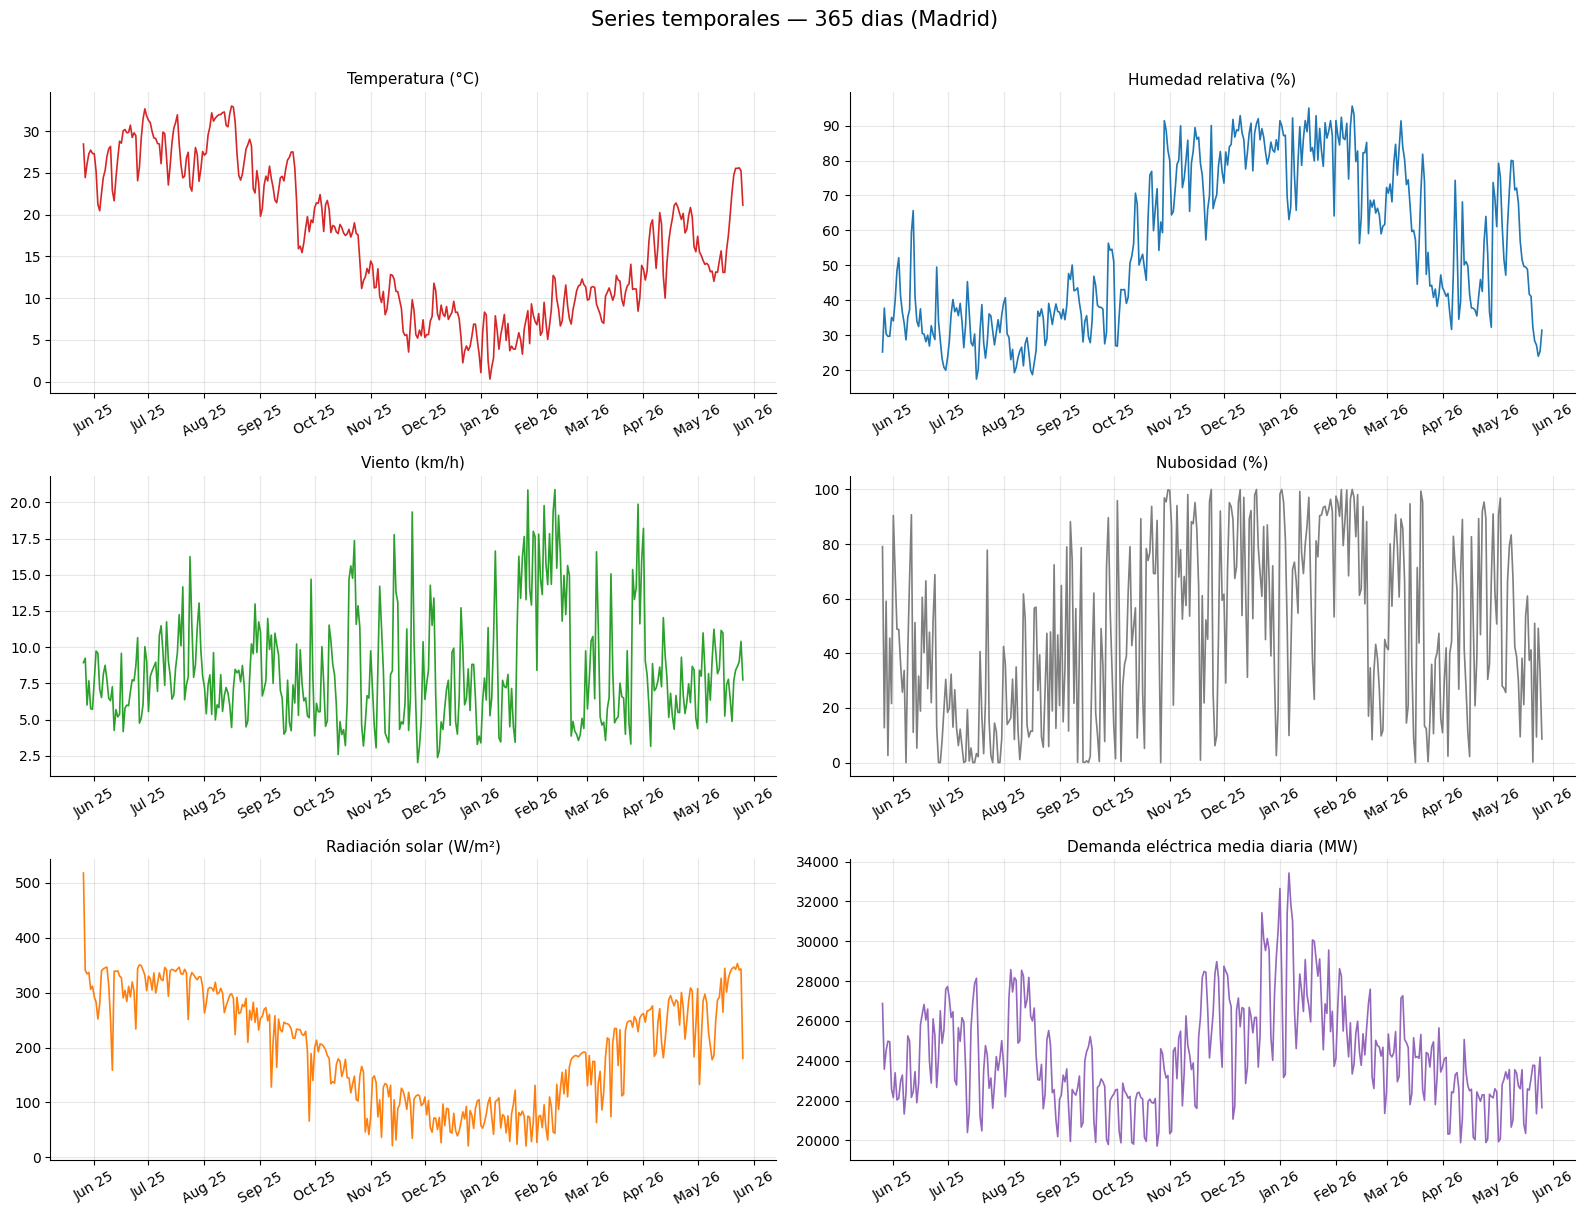

Observa el ciclo estacional en temperatura y radiación solar.
La demanda muestra patrones inversos en verano (refrigeración) e invierno (calefacción).


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Series temporales — 365 dias (Madrid)', fontsize=15, y=1.01)

variables = [
    ('temperature_c',       'Temperatura (°C)',       'tab:red',    weather),
    ('humidity_pct',        'Humedad relativa (%)',   'tab:blue',   weather),
    ('wind_speed_kmh',      'Viento (km/h)',          'tab:green',  weather),
    ('cloud_cover_pct',     'Nubosidad (%)',          'tab:gray',   weather),
    ('solar_radiation_wm2', 'Radiación solar (W/m²)', 'tab:orange', weather),
]

for ax, (col, label, color, src) in zip(axes.flat, variables):
    # Resamplear a diario para que el gráfico anual sea legible
    serie_diaria = src[col].resample('1D').mean()
    ax.plot(serie_diaria.index, serie_diaria.values, color=color, linewidth=1.2)
    ax.set_title(label, fontsize=11)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

# Demanda eléctrica
energia_diaria = energy['demand_mw'].resample('1D').mean()
axes[2, 1].plot(energia_diaria.index, energia_diaria.values, color='tab:purple', linewidth=1.2)
axes[2, 1].set_title('Demanda eléctrica media diaria (MW)', fontsize=11)
axes[2, 1].xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
axes[2, 1].xaxis.set_major_locator(mdates.MonthLocator())
plt.setp(axes[2, 1].xaxis.get_majorticklabels(), rotation=30)

plt.tight_layout()
plt.savefig('01_series_temporales.png', dpi=120, bbox_inches='tight')
plt.show()
print('Observa el ciclo estacional en temperatura y radiación solar.')
print('La demanda muestra patrones inversos en verano (refrigeración) e invierno (calefacción).')

## 5. Distribuciones de frecuencia

Un **histograma** muestra con qué frecuencia aparece cada rango de valores.
Nos dice la "forma" de la variable:

- **Campana de Gauss (normal):** la mayoría de valores cerca de la media
- **Bimodal (dos jorobas):** hay dos grupos distintos (ej: temperatura día/noche)
- **Sesgo a la derecha:** muchos valores bajos y pocos muy altos (ej: viento)
- **Uniforme:** todos los valores son igual de frecuentes

La **línea roja** marca la media. Si está desplazada del centro de la campana,
la distribución está sesgada.


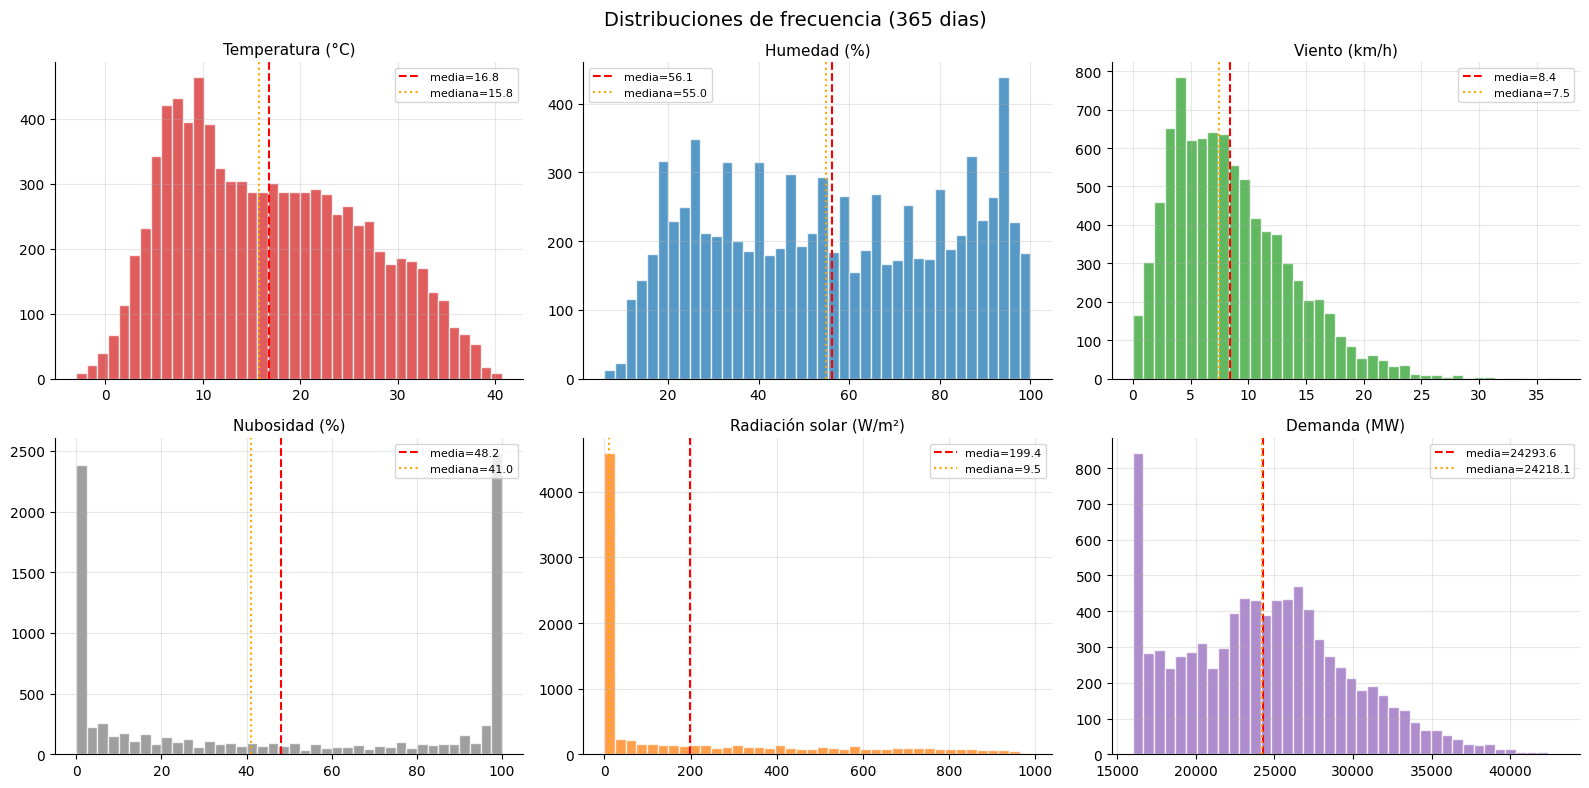

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Distribuciones de frecuencia (365 dias)', fontsize=14)

columnas = ['temperature_c', 'humidity_pct', 'wind_speed_kmh',
            'cloud_cover_pct', 'solar_radiation_wm2', 'demand_mw']
colores  = ['tab:red', 'tab:blue', 'tab:green', 'tab:gray', 'tab:orange', 'tab:purple']
etiquetas = ['Temperatura (°C)', 'Humedad (%)', 'Viento (km/h)',
             'Nubosidad (%)', 'Radiación solar (W/m²)', 'Demanda (MW)']

for ax, col, color, label in zip(axes.flat, columnas, colores, etiquetas):
    datos = df[col].dropna()
    ax.hist(datos, bins=40, color=color, alpha=0.75, edgecolor='white')
    ax.axvline(datos.mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'media={datos.mean():.1f}')
    ax.axvline(datos.median(), color='orange', linestyle=':',  linewidth=1.5, label=f'mediana={datos.median():.1f}')
    ax.set_title(label, fontsize=11)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('01_distribuciones.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Zoom: una semana típica

El gráfico anual es útil para ver tendencias, pero para ver el comportamiento
diario necesitamos hacer zoom. Aquí elegimos una semana representativa de
cada estación para comparar el ciclo día/noche.


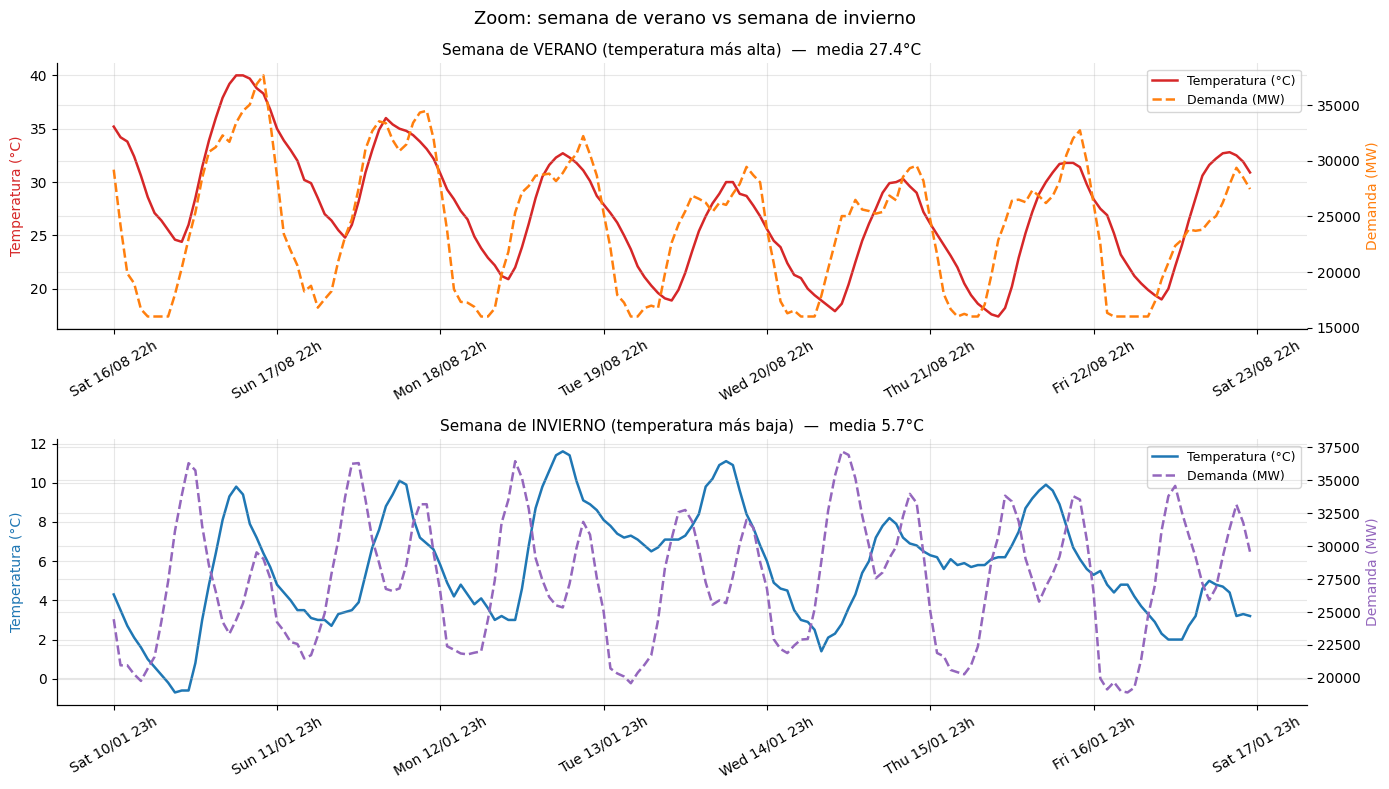

In [7]:
# Elegir una semana de verano y una de invierno del dataset
df_local = df.copy()

# Buscar la semana con temperatura más alta (verano) y más baja (invierno)
temp_semanal = df_local['temperature_c'].resample('1W').mean()
semana_calor  = temp_semanal.idxmax()
semana_frio   = temp_semanal.idxmin()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle('Zoom: semana de verano vs semana de invierno', fontsize=13)

for ax, inicio, titulo, c_temp, c_dem in [
    (axes[0], semana_calor,  'Semana de VERANO (temperatura más alta)', 'tab:red',  'tab:orange'),
    (axes[1], semana_frio,   'Semana de INVIERNO (temperatura más baja)', 'tab:blue', 'tab:purple'),
]:
    from datetime import timedelta
    fin = inicio + pd.Timedelta(days=7)
    mask = (df_local.index >= inicio) & (df_local.index < fin)
    semana = df_local[mask]

    ax2 = ax.twinx()
    ax.plot(semana.index, semana['temperature_c'], color=c_temp, linewidth=1.8, label='Temperatura (°C)')
    ax2.plot(semana.index, semana['demand_mw'],    color=c_dem,  linewidth=1.8, linestyle='--', label='Demanda (MW)')
    ax.set_title(titulo + f'  —  media {semana["temperature_c"].mean():.1f}°C', fontsize=11)
    ax.set_ylabel('Temperatura (°C)', color=c_temp)
    ax2.set_ylabel('Demanda (MW)', color=c_dem)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d/%m %Hh'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30)

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('01_zoom_semanas.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Resumen del análisis exploratorio

Ejecuta las celdas anteriores y anota aquí tus observaciones:

| Variable | Rango observado | Patrón principal | ¿Outliers? |
|----------|----------------|-----------------|-----------|
| Temperatura | ≈ 0–38°C | Ciclo estacional + diario | Olas de calor |
| Humedad | ≈ 10–90% | Inversa a temperatura | - |
| Viento | ≈ 0–50 km/h | Irregular | Episodios de viento |
| Nubosidad | 0–100% | Variable, más alta en otoño/invierno | - |
| Radiación solar | 0–900 W/m² | Cero de noche, máx en verano | - |
| Demanda eléctrica | ≈ 16k–35k MW | U estacional + curva diaria | Festivos |

> **Próximo paso:** ahora que conocemos los datos, en el notebook `02_correlation`
> cuantificamos matemáticamente las relaciones entre clima y demanda.
